In [1]:
import dask.dataframe as dd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

/Users/parikshitnarang/Library/Python/3.9/lib/python/site-packages/dask/dataframe/_pyarrow_compat.py:21: UserWarning: You are using pyarrow version 10.0.1 which is known to be insecure. See https://www.cve.org/CVERecord?id=CVE-2023-47248 for further details. Please upgrade to pyarrow>=14.0.1 or install pyarrow-hotfix to patch your current version.
  warnings.warn(
/Users/parikshitnarang/Library/Python/3.9/lib/python/site-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


In [2]:
def load_all_data_dask(base_dir):
    all_data = []
    for year_folder in os.listdir(base_dir):
        if not year_folder.startswith('year='):
            continue
        
        year_dir = os.path.join(base_dir, year_folder)
        
        year_files = [f for f in os.listdir(year_dir) if f.endswith('.parquet')]

        for file in year_files:
            file_path = os.path.join(year_dir, file)
            try:
                df = dd.read_parquet(file_path)
                df['year'] = int(year_folder.split('=')[1])
                all_data.append(df)
            except Exception as e:
                print(f"Skipping file {file_path} due to error: {e}")
    
    if not all_data:
        raise ValueError("No data files were successfully loaded.")
    
    full_df = dd.concat(all_data, axis=0)
    return full_df

In [3]:
base_dir = "../../accepted_by_year"  
try:
    df_all = load_all_data_dask(base_dir)
    
    df_all = df_all.compute()  
    print(f"Data loaded successfully. Shape: {df_all.shape}")
except Exception as e:
    print(f"Error during loading data: {e}")
    df_all = None 

Data loaded successfully. Shape: (2260667, 153)


Available columns: Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       ...
       'disbursement_method', 'debt_settlement_flag',
       'debt_settlement_flag_date', 'settlement_status', 'settlement_date',
       'settlement_amount', 'settlement_percentage', 'settlement_term',
       'year_bucket', 'year'],
      dtype='object', length=153)
Created 'loan_status_binary' from 'loan_status'.


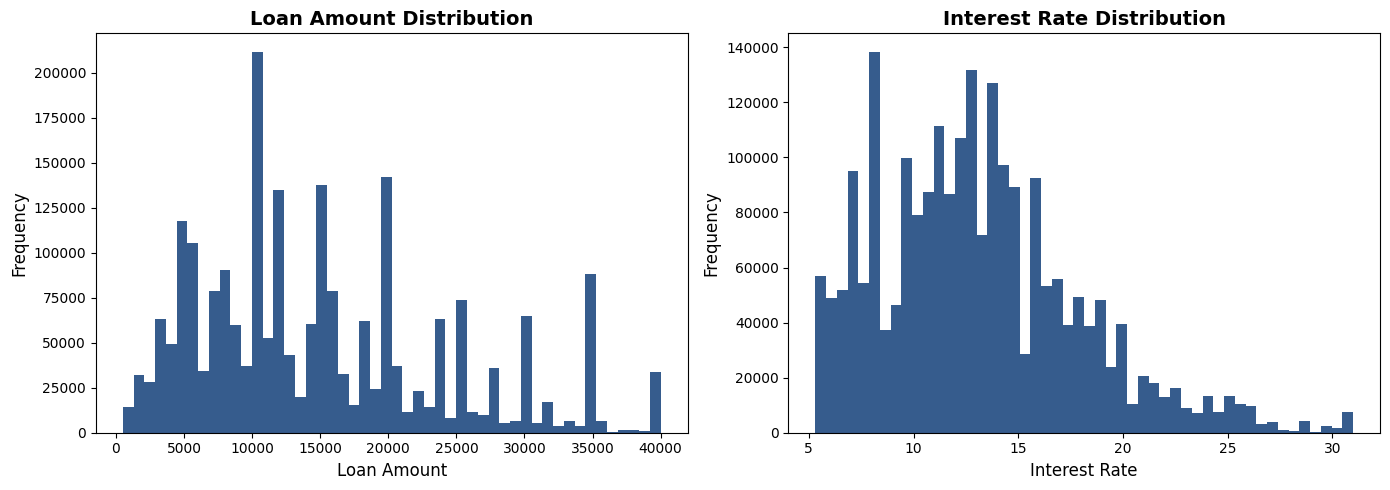

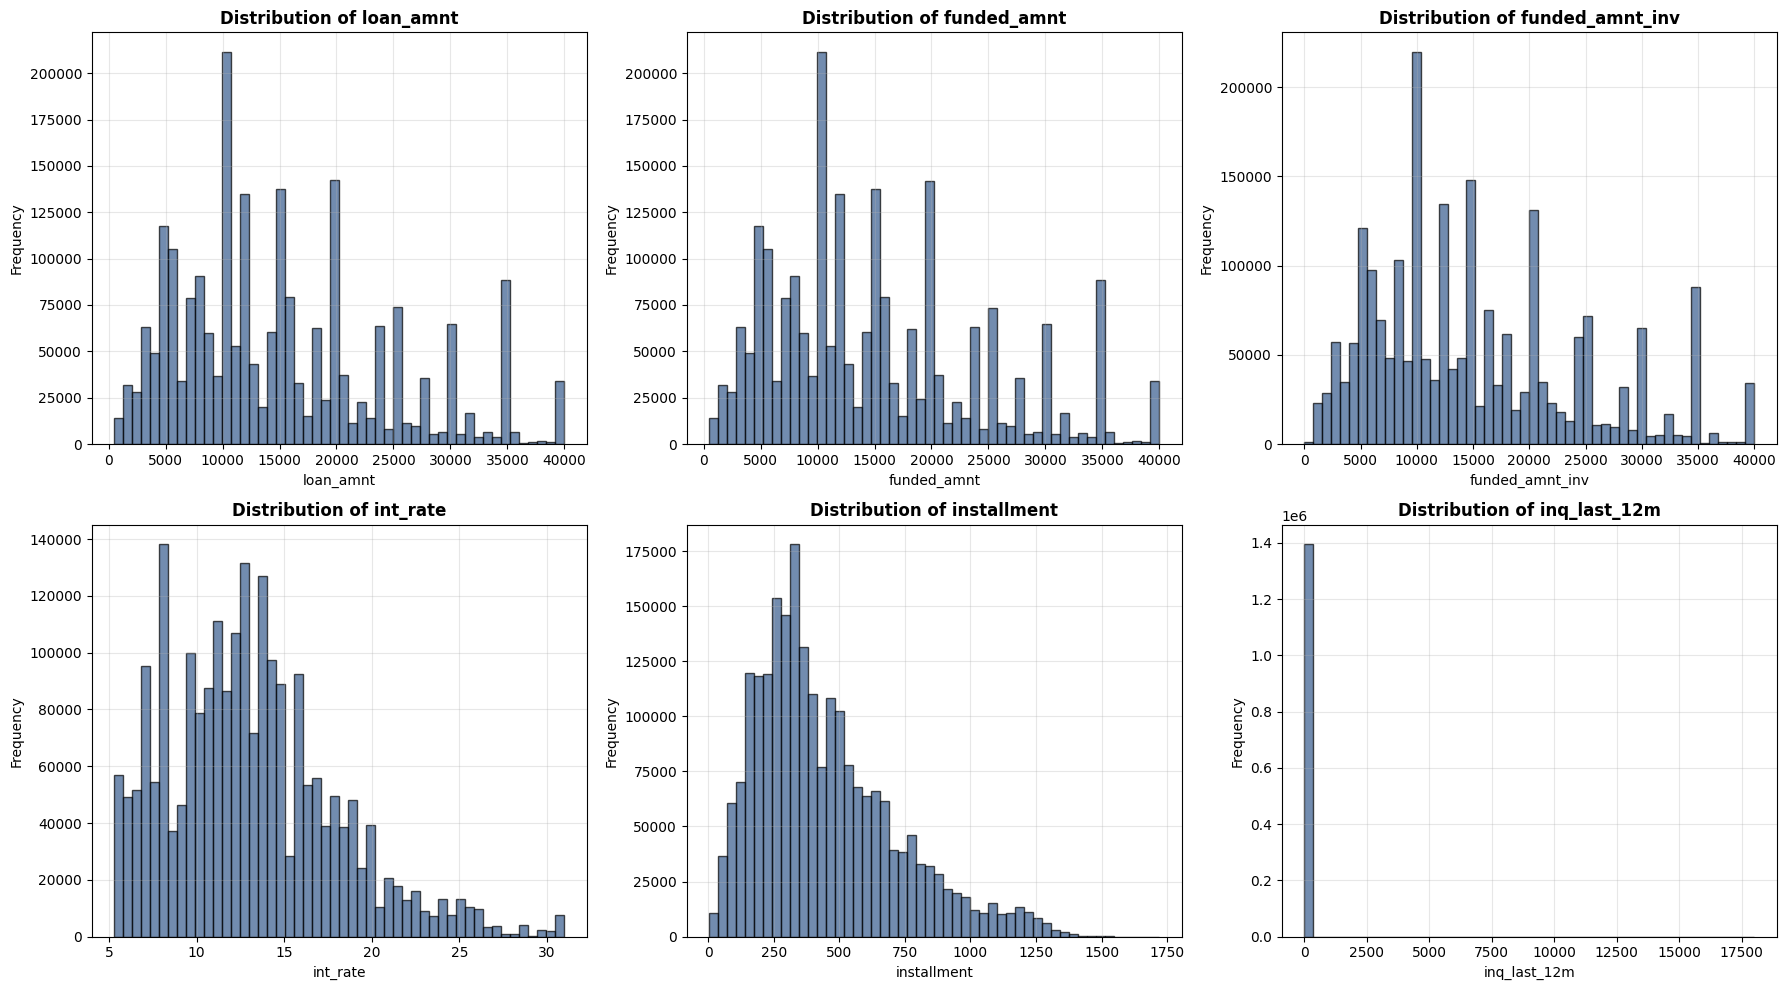

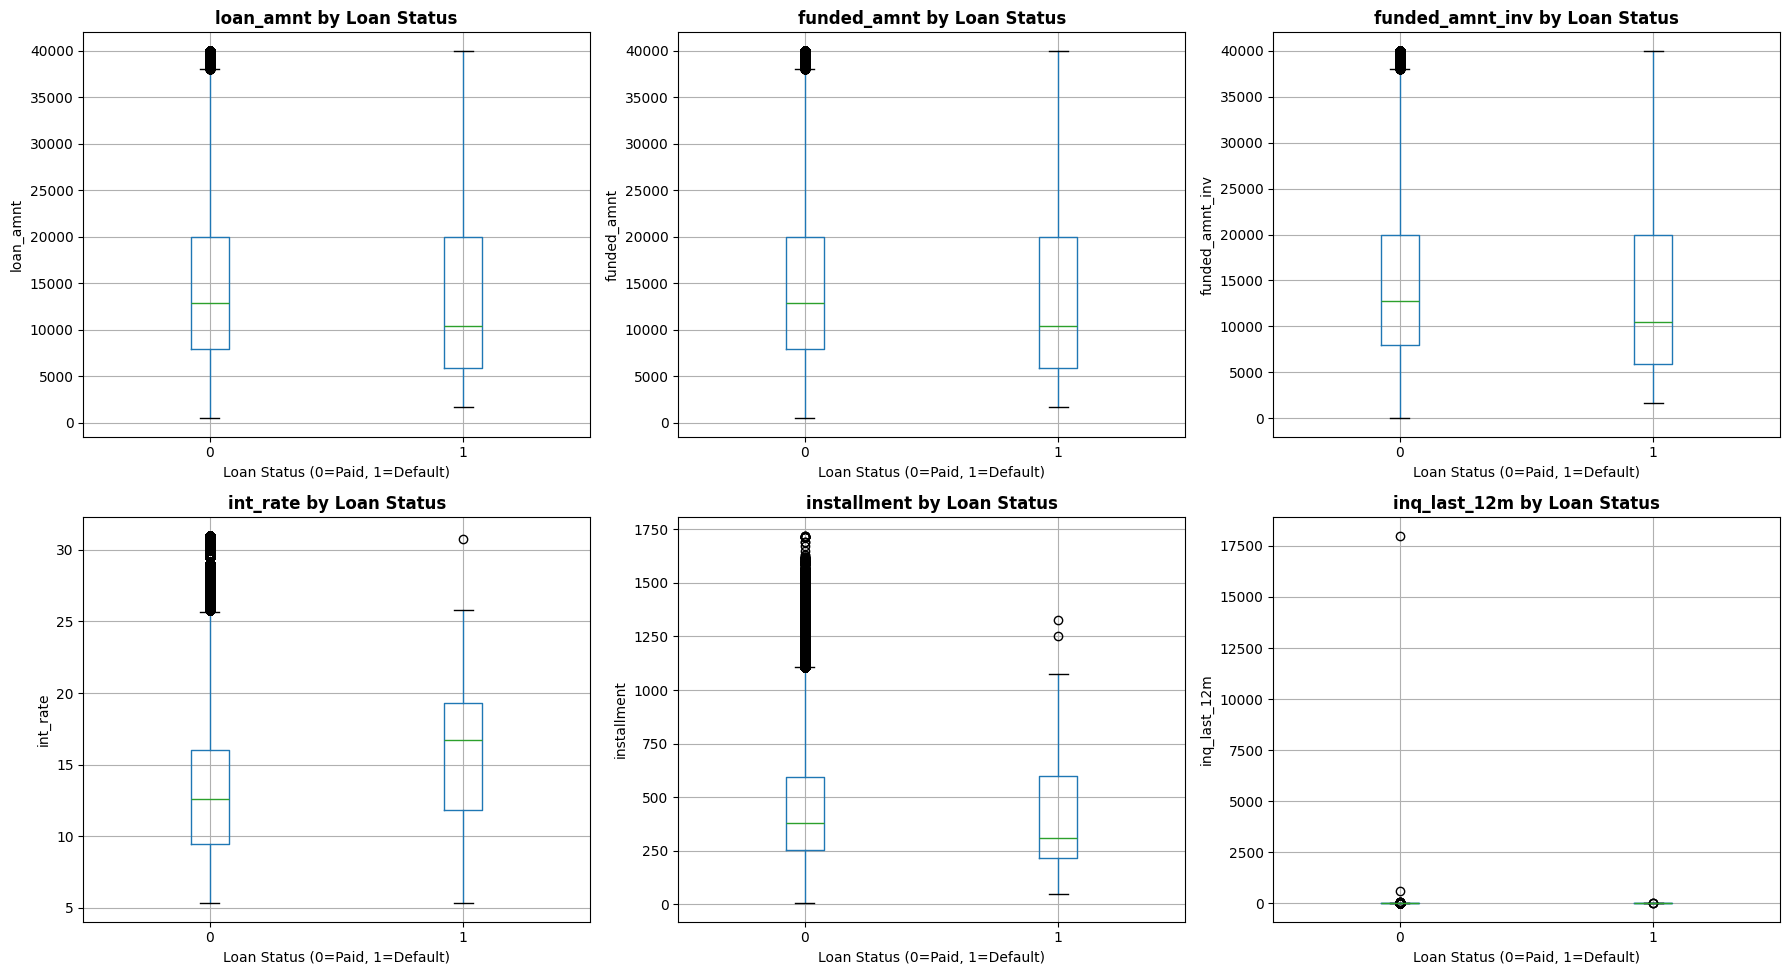

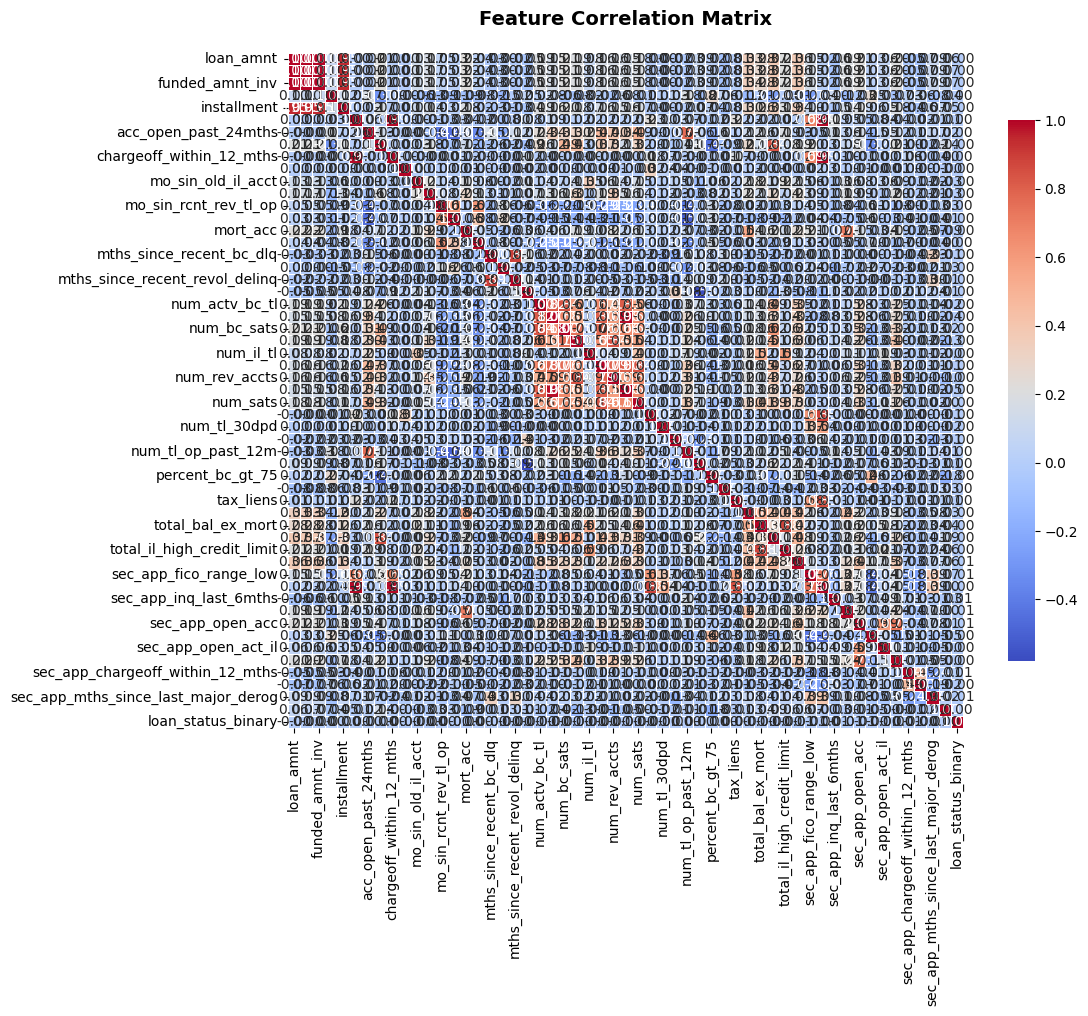

In [4]:
def eda_before_preprocessing(df):
    if 'loan_status_binary' not in df.columns:
        print("Warning: 'loan_status_binary' column is not found in the data.")
        print("Available columns:", df.columns)

        if 'loan_status' in df.columns:
            df['loan_status_binary'] = df['loan_status'].apply(lambda x: 1 if x == 'Default' else 0)
            print("Created 'loan_status_binary' from 'loan_status'.")
        else:
            print("Neither 'loan_status_binary' nor 'loan_status' found.")
    
    # Filter numeric columns for EDA
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

    # Distribution of key numerical features
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    if 'loan_amnt' in df.columns:
        df['loan_amnt'].plot(kind='hist', ax=axes[0], color=sns.color_palette("viridis")[1], bins=50)
        axes[0].set_title('Loan Amount Distribution', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Loan Amount', fontsize=12)
        axes[0].set_ylabel('Frequency', fontsize=12)

    if 'int_rate' in df.columns:
        df['int_rate'].plot(kind='hist', ax=axes[1], color=sns.color_palette("viridis")[1], bins=50)
        axes[1].set_title('Interest Rate Distribution', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Interest Rate', fontsize=12)
        axes[1].set_ylabel('Frequency', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Distribution of other numerical features
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for idx, col in enumerate(numerical_features):
        if idx < len(axes):
            df[col].plot(kind='hist', ax=axes[idx], bins=50, alpha=0.7, color=sns.color_palette("viridis")[1], edgecolor='black')
            axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(col, fontsize=10)
            axes[idx].set_ylabel('Frequency', fontsize=10)
            axes[idx].grid(alpha=0.3)

    # Hide unused subplots
    for idx in range(len(numerical_features), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

    # Feature comparison by loan status (if 'loan_status_binary' is available)
    if 'loan_status_binary' in df.columns:
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.ravel()

        for idx, col in enumerate(numerical_features):
            if idx < len(axes):
                df.boxplot(column=col, by='loan_status_binary', ax=axes[idx])  # Simplified color
                axes[idx].set_title(f'{col} by Loan Status', fontsize=12, fontweight='bold')
                axes[idx].set_xlabel('Loan Status (0=Paid, 1=Default)', fontsize=10)
                axes[idx].set_ylabel(col, fontsize=10)

        # Skip unused Plots
        for idx in range(len(numerical_features), len(axes)):
            axes[idx].axis('off')

        plt.suptitle('')
        plt.tight_layout()
        plt.show()

    # Correlation heatmap for numeric features
    if len(numerical_features) > 0:
        plt.figure(figsize=(12, 10))
        correlation_matrix = df[numerical_features].corr()
        sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap="coolwarm", 
                    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()

# Run the EDA on the full dataset if it was successfully loaded
if df_all is not None:
    eda_before_preprocessing(df_all)
else:
    print("Data loading failed. EDA not performed.")